In [4]:
# ===================================
# Importation des bibliothèques
# ===================================


import os

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns


from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)


from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    GRU,
    RepeatVector,
    TimeDistributed,
    Dense
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)


# ===================================
# Configuration générale
# ===================================


np.random.seed(42)


plt.rcParams["font.family"] = "Consolas"

plt.rcParams["figure.dpi"] = 300

plt.rcParams["savefig.dpi"] = 300


# ===================================
# Dossier de sauvegarde des figures
# ===================================


FIGURE_DIR = "figures_gru_autoencoder"


os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


print(
    "Bibliothèques importées avec succès."
)

print(
    f"Dossier des figures : {FIGURE_DIR}"
)

Bibliothèques importées avec succès.
Dossier des figures : figures_gru_autoencoder


In [5]:
dataset_path = "UNSW-NB15_1.csv"
df = pd.read_csv(dataset_path, header = None,low_memory=False)

In [6]:
columns = [
    'srcip','sport','dstip','dsport','proto','state',
    'dur','sbytes','dbytes','sttl','dttl','sloss','dloss',
    'service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz',
    'trans_depth','res_bdy_len','Sjit','Djit',
    'Stime','Ltime','Sintpkt','Dintpkt',
    'tcprtt','synack','ackdat','is_sm_ips_ports',
    'ct_state_ttl','ct_flw_http_mthd','is_ftp_login',
    'ct_ftp_cmd','ct_srv_src','ct_srv_dst',
    'ct_dst_ltm','ct_src_ltm',
    'ct_src_dport_ltm','ct_dst_sport_ltm',
    'ct_dst_src_ltm','attack_cat','label'
]
df.columns = columns

In [7]:
# ===================================
# Valeurs manquantes
# ===================================


missing_values = df.isnull().sum()

missing_values[missing_values > 0]

attack_cat    677786
dtype: int64

In [8]:
target_column = "label"

In [9]:
# ===================================
# Séparation X / y
# ===================================


X = df.drop(
    columns=[target_column]
)


y = df[
    target_column
].copy()


In [10]:
print(
    "Dimensions des variables d'entrée :",
    X.shape
)


print(
    "Dimensions de la cible :",
    y.shape
)

Dimensions des variables d'entrée : (700001, 48)
Dimensions de la cible : (700001,)


Valeurs présentes dans la cible :
label
0    677786
1     22215
Name: count, dtype: int64

Répartition en pourcentage :
label
0    96.83
1     3.17
Name: proportion, dtype: float64


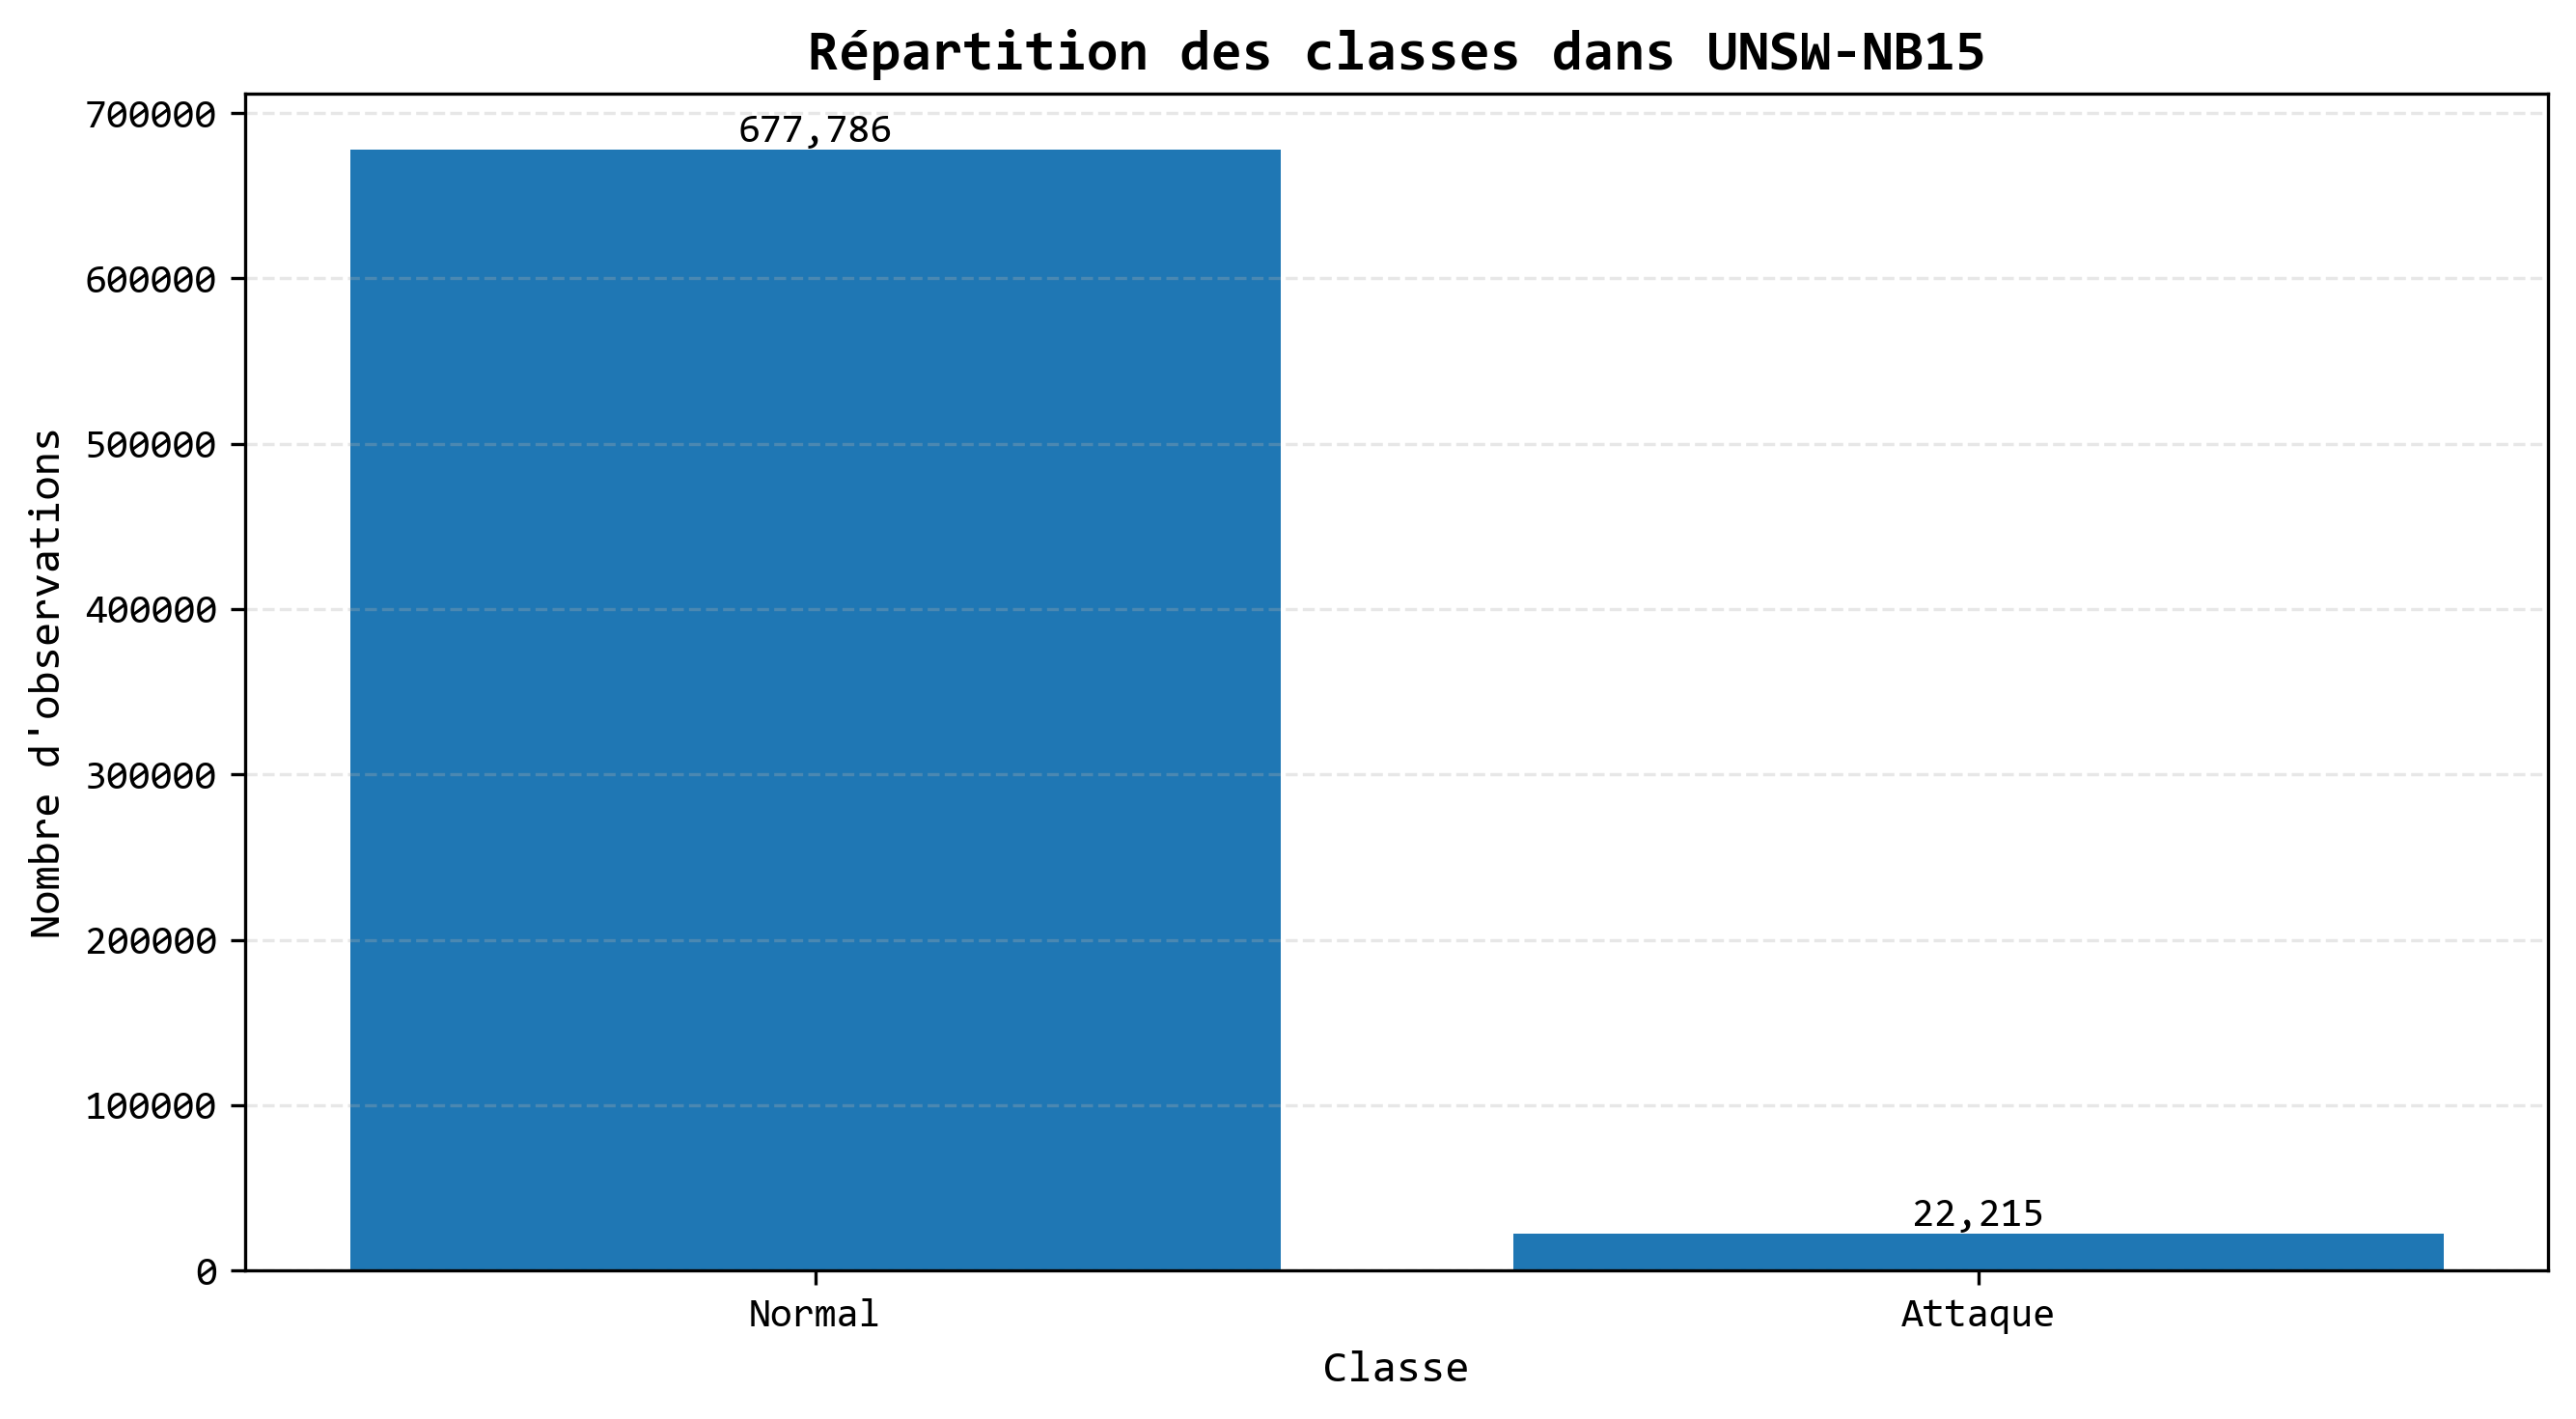

Figure sauvegardée : figures_gru_autoencoder\01_repartition_classes.png


In [12]:
# ===================================
# Analyse de la variable cible
# ===================================


TARGET = "label"


print(
    "Valeurs présentes dans la cible :"
)


print(
    df[TARGET].value_counts()
)


print(
    "\nRépartition en pourcentage :"
)


print(
    df[TARGET]
    .value_counts(
        normalize=True
    )
    .mul(100)
    .round(2)
)


# ===================================
# Préparation des données du graphique
# ===================================


class_distribution = (
    df[TARGET]
    .value_counts()
    .sort_index()
)


class_names = [
    "Normal",
    "Attaque"
]


# ===================================
# Graphique
# ===================================


fig, ax = plt.subplots(
    figsize=(9, 5)
)


bars = ax.bar(
    class_names,
    class_distribution.values
)


# ===================================
# Valeurs au-dessus des barres
# ===================================


for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontfamily="Consolas"
    )


# ===================================
# Présentation scientifique
# ===================================


ax.set_title(
    "Répartition des classes dans UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas"
)


ax.set_xlabel(
    "Classe",
    fontsize=11,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily="Consolas"
)


ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


plt.tight_layout()


# ===================================
# Sauvegarde
# ===================================


figure_path = os.path.join(
    FIGURE_DIR,
    "01_repartition_classes.png"
)


plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    f"Figure sauvegardée : {figure_path}"
)

In [15]:
# ===================================
# Nettoyage des données
# ===================================


df_clean = df.copy()

# ===================================
# Suppression des doublons
# ===================================


duplicates_before = (
    df_clean
    .duplicated()
    .sum()
)


df_clean = (
    df_clean
    .drop_duplicates()
    .reset_index(
        drop=True
    )
)

# ===================================
# Remplacement des valeurs infinies
# ===================================


numeric_columns = (
    df_clean
    .select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
)


df_clean[
    numeric_columns
] = (
    df_clean[
        numeric_columns
    ]
    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ===================================
# Valeurs manquantes
# ===================================


missing_before = (
    df_clean
    .isnull()
    .sum()
    .sum()
)

# ===================================
# Colonnes numériques :
# remplacement par la médiane
# ===================================


for column in numeric_columns:

    if df_clean[
        column
    ].isnull().any():

        median_value = (
            df_clean[
                column
            ]
            .median()
        )

        df_clean[
            column
        ] = (
            df_clean[
                column
            ]
            .fillna(
                median_value
            )
        )


# ===================================
# Colonnes catégorielles :
# remplacement par le mode
# ===================================


categorical_columns = (
    df_clean
    .select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
)


for column in categorical_columns:

    if df_clean[
        column
    ].isnull().any():

        mode_values = (
            df_clean[
                column
            ]
            .mode()
        )

        if len(
            mode_values
        ) > 0:

            fill_value = (
                mode_values.iloc[0]
            )

        else:

            fill_value = "unknown"


        df_clean[
            column
        ] = (
            df_clean[
                column
            ]
            .fillna(
                fill_value
            )
        )


# ===================================
# Vérification finale
# ===================================


missing_after = (
    df_clean
    .isnull()
    .sum()
    .sum()
)


infinite_after = (
    np.isinf(
        df_clean[
            numeric_columns
        ]
        .to_numpy()
    )
    .sum()
)




In [17]:
# ===================================
# Préparation des variables
# GRU Autoencoder - UNSW-NB15
# ===================================


TARGET = "label"


# ===================================
# Vérification de la cible
# ===================================


if TARGET not in df_clean.columns:

    raise ValueError(
        f"La colonne cible '{TARGET}' "
        "n'existe pas dans le dataset."
    )


# ===================================
# Séparation X / y
# ===================================


X = (
    df_clean
    .drop(
        columns=[
            TARGET
        ]
    )
    .copy()
)


y = (
    df_clean[
        TARGET
    ]
    .astype(int)
    .copy()
)


print(
    "Dimensions initiales de X :",
    X.shape
)


print(
    "Dimensions de y :",
    y.shape
)


# ===================================
# Suppression de attack_cat
# ===================================
# Cette variable révèle directement
# la catégorie d'attaque.
# Son utilisation provoquerait une
# fuite d'information.
# ===================================


if "attack_cat" in X.columns:

    X = X.drop(
        columns=[
            "attack_cat"
        ]
    )

    print(
        "\nColonne 'attack_cat' supprimée."
    )


# ===================================
# Suppression des adresses IP
# ===================================
# srcip et dstip sont des identifiants
# à très forte cardinalité.
#
# Leur One-Hot Encoding créerait des
# dizaines de milliers de colonnes.
# ===================================


high_cardinality_columns = [
    "srcip",
    "dstip"
]


columns_to_drop = [
    column
    for column in high_cardinality_columns
    if column in X.columns
]


if columns_to_drop:

    X = X.drop(
        columns=columns_to_drop
    )


print(
    "\nColonnes à forte cardinalité supprimées :",
    columns_to_drop
)


# ===================================
# Traitement des ports
# ===================================
# sport et dsport doivent être
# numériques et non catégoriels.
# ===================================


port_columns = [
    "sport",
    "dsport"
]


for column in port_columns:

    if column in X.columns:

        # Conversion des valeurs
        # hexadécimales éventuelles

        def convert_port(value):

            try:

                value = str(
                    value
                ).strip()

                if value.lower().startswith(
                    "0x"
                ):

                    return int(
                        value,
                        16
                    )

                return float(
                    value
                )

            except:

                return np.nan


        X[column] = (
            X[column]
            .apply(
                convert_port
            )
        )


        # Remplacement des valeurs
        # non convertibles par la médiane

        X[column] = (
            X[column]
            .fillna(
                X[column].median()
            )
        )


# ===================================
# Variables réellement catégorielles
# ===================================


candidate_categorical_features = [
    "proto",
    "service",
    "state"
]


categorical_features = [
    column
    for column
    in candidate_categorical_features
    if column in X.columns
]


print(
    "\nVariables catégorielles retenues :"
)


for column in categorical_features:

    print(
        f" - {column} : "
        f"{X[column].nunique()} modalités"
    )


# ===================================
# Vérification des autres colonnes
# object
# ===================================


remaining_object_columns = (
    X
    .select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
    .tolist()
)


print(
    "\nColonnes encore reconnues comme "
    "catégorielles avant encodage :"
)


for column in remaining_object_columns:

    print(
        f" - {column} : "
        f"{X[column].nunique()} valeurs uniques"
    )


# ===================================
# Suppression prudente des éventuelles
# colonnes texte à très forte cardinalité
# ===================================


extra_high_cardinality = []


for column in remaining_object_columns:

    if (
        column not in categorical_features
        and
        X[column].nunique() > 100
    ):

        extra_high_cardinality.append(
            column
        )


if extra_high_cardinality:

    print(
        "\nColonnes supplémentaires "
        "à forte cardinalité supprimées :"
    )


    for column in extra_high_cardinality:

        print(
            f" - {column}"
        )


    X = X.drop(
        columns=extra_high_cardinality
    )


# ===================================
# Identification finale des variables
# catégorielles
# ===================================


categorical_features = [
    column
    for column in [
        "proto",
        "service",
        "state"
    ]
    if column in X.columns
]


# ===================================
# One-Hot Encoding
# uniquement des petites variables
# catégorielles
# ===================================


X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=False,
    dtype=np.float32
)


# ===================================
# Conversion des colonnes restantes
# ===================================


for column in X_encoded.columns:

    if not pd.api.types.is_numeric_dtype(
        X_encoded[column]
    ):

        X_encoded[column] = pd.to_numeric(
            X_encoded[column],
            errors="coerce"
        )


# ===================================
# Traitement d'éventuels NaN
# après conversion
# ===================================


X_encoded = X_encoded.replace(
    [
        np.inf,
        -np.inf
    ],
    np.nan
)


numeric_medians = (
    X_encoded
    .median(
        numeric_only=True
    )
)


X_encoded = (
    X_encoded
    .fillna(
        numeric_medians
    )
)


# ===================================
# Conversion mémoire efficace
# ===================================


X_encoded = (
    X_encoded
    .astype(
        np.float32
    )
)


# ===================================
# Vérification finale
# ===================================


print(
    "\nDimensions après encodage :",
    X_encoded.shape
)


print(
    "Nombre final de features :",
    X_encoded.shape[1]
)


print(
    "Type principal :",
    X_encoded.dtypes.iloc[0]
)


print(
    "\nMémoire utilisée : "
    f"{X_encoded.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)


print(
    "\nValeurs manquantes restantes :",
    X_encoded.isnull().sum().sum()
)


print(
    "\nPrétraitement terminé avec succès."
)

Dimensions initiales de X : (640788, 48)
Dimensions de y : (640788,)

Colonne 'attack_cat' supprimée.

Colonnes à forte cardinalité supprimées : ['srcip', 'dstip']

Variables catégorielles retenues :
 - proto : 135 modalités
 - service : 13 modalités
 - state : 16 modalités

Colonnes encore reconnues comme catégorielles avant encodage :
 - proto : 135 valeurs uniques
 - state : 16 valeurs uniques
 - service : 13 valeurs uniques

Dimensions après encodage : (640788, 206)
Nombre final de features : 206
Type principal : float32

Mémoire utilisée : 503.55 MB

Valeurs manquantes restantes : 0

Prétraitement terminé avec succès.


In [18]:
# ===================================
# Séparation Normal / Attaque
# ===================================


normal_mask = (
    y == 0
)


attack_mask = (
    y == 1
)


X_normal = (
    X_encoded[
        normal_mask
    ]
    .copy()
)


X_attack = (
    X_encoded[
        attack_mask
    ]
    .copy()
)


print(
    "Trafic normal :",
    X_normal.shape
)


print(
    "Trafic d'attaque :",
    X_attack.shape
)


print(
    "\nNombre d'observations normales :",
    len(
        X_normal
    )
)


print(
    "Nombre d'observations d'attaque :",
    len(
        X_attack
    )
)


# ===================================
# Vérification des proportions
# ===================================


total_samples = (
    len(
        X_normal
    )
    +
    len(
        X_attack
    )
)


normal_percentage = (
    len(
        X_normal
    )
    /
    total_samples
    *
    100
)


attack_percentage = (
    len(
        X_attack
    )
    /
    total_samples
    *
    100
)


print(
    f"\nTrafic normal : "
    f"{normal_percentage:.2f}%"
)


print(
    f"Trafic d'attaque : "
    f"{attack_percentage:.2f}%"
)

Trafic normal : (626510, 206)
Trafic d'attaque : (14278, 206)

Nombre d'observations normales : 626510
Nombre d'observations d'attaque : 14278

Trafic normal : 97.77%
Trafic d'attaque : 2.23%


In [19]:
print(X_encoded.shape)
print(X_encoded.memory_usage(deep=True).sum() / 1024**2)

(640788, 206)
503.5490417480469


In [20]:
# ===================================
# Séparation Train / Validation / Test
# GRU Autoencoder
# ===================================


RANDOM_STATE = 42


# ===================================
# 1. Séparation du trafic normal
# ===================================
# 70 %  -> entraînement
# 15 %  -> validation
# 15 %  -> test normal
# ===================================


X_train_normal, X_temp_normal = train_test_split(

    X_normal,

    test_size=0.30,

    random_state=RANDOM_STATE,

    shuffle=True

)


X_val_normal, X_test_normal = train_test_split(

    X_temp_normal,

    test_size=0.50,

    random_state=RANDOM_STATE,

    shuffle=True

)


# ===================================
# Vérification des dimensions
# ===================================


print(
    "=== Trafic normal ==="
)


print(
    "Train normal      :",
    X_train_normal.shape
)


print(
    "Validation normal :",
    X_val_normal.shape
)


print(
    "Test normal       :",
    X_test_normal.shape
)


print(
    "\nAttaques réservées au test :",
    X_attack.shape
)


# ===================================
# 2. Création du jeu de test complet
# ===================================
# Le jeu de test contient :
#
# label = 0 -> trafic normal
# label = 1 -> trafic d'attaque
# ===================================


X_test = pd.concat(

    [
        X_test_normal,
        X_attack
    ],

    axis=0

)


y_test = np.concatenate(

    [

        np.zeros(
            len(X_test_normal),
            dtype=np.int32
        ),

        np.ones(
            len(X_attack),
            dtype=np.int32
        )

    ]

)


# ===================================
# Mélange du jeu de test
# ===================================


rng = np.random.RandomState(
    RANDOM_STATE
)


test_indices = rng.permutation(
    len(X_test)
)


X_test = (
    X_test
    .iloc[test_indices]
    .reset_index(
        drop=True
    )
)


y_test = y_test[
    test_indices
]


# ===================================
# 3. Normalisation
# ===================================
# IMPORTANT :
#
# Le scaler est entraîné uniquement
# sur le trafic normal du TRAIN.
#
# Cela évite le data leakage.
# ===================================


scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(

    X_train_normal

)


X_val_scaled = scaler.transform(

    X_val_normal

)


X_test_scaled = scaler.transform(

    X_test

)


# ===================================
# Conversion float32
# ===================================
# Réduction de la mémoire utilisée
# et format adapté à TensorFlow.
# ===================================


X_train_scaled = (
    X_train_scaled
    .astype(
        np.float32
    )
)


X_val_scaled = (
    X_val_scaled
    .astype(
        np.float32
    )
)


X_test_scaled = (
    X_test_scaled
    .astype(
        np.float32
    )
)


# ===================================
# Vérification des NaN / Inf
# ===================================


print(
    "\n=== Vérification après normalisation ==="
)


print(
    "NaN Train :",
    np.isnan(
        X_train_scaled
    ).sum()
)


print(
    "NaN Validation :",
    np.isnan(
        X_val_scaled
    ).sum()
)


print(
    "NaN Test :",
    np.isnan(
        X_test_scaled
    ).sum()
)


print(
    "\nInf Train :",
    np.isinf(
        X_train_scaled
    ).sum()
)


print(
    "Inf Validation :",
    np.isinf(
        X_val_scaled
    ).sum()
)


print(
    "Inf Test :",
    np.isinf(
        X_test_scaled
    ).sum()
)


# ===================================
# 4. Informations finales
# ===================================


print(
    "\n=== Dimensions finales ==="
)


print(
    "X_train_scaled :",
    X_train_scaled.shape
)


print(
    "X_val_scaled   :",
    X_val_scaled.shape
)


print(
    "X_test_scaled  :",
    X_test_scaled.shape
)


print(
    "y_test         :",
    y_test.shape
)


# ===================================
# Distribution du jeu de test
# ===================================


unique_labels, counts = np.unique(

    y_test,

    return_counts=True

)


print(
    "\n=== Distribution du jeu de test ==="
)


for label, count in zip(

    unique_labels,

    counts

):


    class_name = (

        "Normal"

        if label == 0

        else "Attaque"

    )


    percentage = (

        count
        /
        len(y_test)
        *
        100

    )


    print(

        f"{class_name:<10} : "
        f"{count:,} "
        f"({percentage:.2f}%)"

    )


# ===================================
# Vérification finale
# ===================================


assert (
    X_train_scaled.shape[1]
    ==
    X_val_scaled.shape[1]
    ==
    X_test_scaled.shape[1]
), "Le nombre de features est incohérent."


assert (
    len(X_test_scaled)
    ==
    len(y_test)
), "X_test et y_test n'ont pas la même taille."


print(
    "\nSéparation et normalisation "
    "terminées avec succès."
)

=== Trafic normal ===
Train normal      : (438557, 206)
Validation normal : (93976, 206)
Test normal       : (93977, 206)

Attaques réservées au test : (14278, 206)

=== Vérification après normalisation ===
NaN Train : 0
NaN Validation : 0
NaN Test : 0

Inf Train : 0
Inf Validation : 0
Inf Test : 0

=== Dimensions finales ===
X_train_scaled : (438557, 206)
X_val_scaled   : (93976, 206)
X_test_scaled  : (108255, 206)
y_test         : (108255,)

=== Distribution du jeu de test ===
Normal     : 93,977 (86.81%)
Attaque    : 14,278 (13.19%)

Séparation et normalisation terminées avec succès.


In [21]:
# ===================================
# Transformation des données en 3D
# GRU Autoencoder
# ===================================


# ===================================
# Dimensions avant transformation
# ===================================


print(
    "=== Dimensions avant reshape ==="
)


print(
    "Train      :",
    X_train_scaled.shape
)


print(
    "Validation :",
    X_val_scaled.shape
)


print(
    "Test       :",
    X_test_scaled.shape
)


# ===================================
# Nombre de variables
# ===================================


n_features = (
    X_train_scaled.shape[1]
)


print(
    "\nNombre de features :",
    n_features
)


# ===================================
# Transformation au format GRU
# ===================================
#
# Avant :
#
# (samples, features)
#
# Après :
#
# (samples, timesteps, 1)
#
# Ici :
#
# timesteps = nombre de features
#
# ===================================


X_train_gru = X_train_scaled.reshape(

    X_train_scaled.shape[0],

    X_train_scaled.shape[1],

    1

)


X_val_gru = X_val_scaled.reshape(

    X_val_scaled.shape[0],

    X_val_scaled.shape[1],

    1

)


X_test_gru = X_test_scaled.reshape(

    X_test_scaled.shape[0],

    X_test_scaled.shape[1],

    1

)


# ===================================
# Conversion en float32
# ===================================


X_train_gru = (
    X_train_gru
    .astype(
        np.float32
    )
)


X_val_gru = (
    X_val_gru
    .astype(
        np.float32
    )
)


X_test_gru = (
    X_test_gru
    .astype(
        np.float32
    )
)


# ===================================
# Vérification des dimensions
# ===================================


print(
    "\n=== Dimensions après reshape ==="
)


print(
    "X_train_gru :",
    X_train_gru.shape
)


print(
    "X_val_gru   :",
    X_val_gru.shape
)


print(
    "X_test_gru  :",
    X_test_gru.shape
)


# ===================================
# Vérification de la structure
# ===================================


print(
    "\nNombre d'échantillons Train :",
    X_train_gru.shape[0]
)


print(
    "Nombre de timesteps :",
    X_train_gru.shape[1]
)


print(
    "Nombre de features par timestep :",
    X_train_gru.shape[2]
)


# ===================================
# Vérification NaN / Inf
# ===================================


print(
    "\n=== Vérification des données ==="
)


print(
    "NaN Train :",
    np.isnan(
        X_train_gru
    ).sum()
)


print(
    "NaN Validation :",
    np.isnan(
        X_val_gru
    ).sum()
)


print(
    "NaN Test :",
    np.isnan(
        X_test_gru
    ).sum()
)


print(
    "\nInf Train :",
    np.isinf(
        X_train_gru
    ).sum()
)


print(
    "Inf Validation :",
    np.isinf(
        X_val_gru
    ).sum()
)


print(
    "Inf Test :",
    np.isinf(
        X_test_gru
    ).sum()
)


# ===================================
# Vérifications automatiques
# ===================================


assert X_train_gru.ndim == 3, (
    "X_train_gru doit avoir 3 dimensions."
)


assert X_val_gru.ndim == 3, (
    "X_val_gru doit avoir 3 dimensions."
)


assert X_test_gru.ndim == 3, (
    "X_test_gru doit avoir 3 dimensions."
)


assert (
    X_train_gru.shape[1]
    ==
    X_val_gru.shape[1]
    ==
    X_test_gru.shape[1]
), (
    "Le nombre de timesteps est incohérent."
)


assert (
    X_train_gru.shape[2]
    ==
    X_val_gru.shape[2]
    ==
    X_test_gru.shape[2]
    ==
    1
), (
    "La dernière dimension doit être égale à 1."
)


print(
    "\nTransformation 3D terminée avec succès."
)

=== Dimensions avant reshape ===
Train      : (438557, 206)
Validation : (93976, 206)
Test       : (108255, 206)

Nombre de features : 206

=== Dimensions après reshape ===
X_train_gru : (438557, 206, 1)
X_val_gru   : (93976, 206, 1)
X_test_gru  : (108255, 206, 1)

Nombre d'échantillons Train : 438557
Nombre de timesteps : 206
Nombre de features par timestep : 1

=== Vérification des données ===
NaN Train : 0
NaN Validation : 0
NaN Test : 0

Inf Train : 0
Inf Validation : 0
Inf Test : 0

Transformation 3D terminée avec succès.


In [22]:
# ===================================
# Construction du GRU Autoencoder
# ===================================


# ===================================
# Dimensions d'entrée
# ===================================


timesteps = (
    X_train_gru.shape[1]
)


features_per_timestep = (
    X_train_gru.shape[2]
)


print(
    "Timesteps :",
    timesteps
)


print(
    "Features par timestep :",
    features_per_timestep
)


# ===================================
# Couche d'entrée
# ===================================


input_layer = Input(

    shape=(
        timesteps,
        features_per_timestep
    ),

    name="Input_Layer"

)


# ===================================
# Encodeur GRU
# ===================================


x = GRU(

    units=64,

    activation="tanh",

    return_sequences=True,

    name="GRU_Encoder_1"

)(
    input_layer
)


x = GRU(

    units=32,

    activation="tanh",

    return_sequences=False,

    name="GRU_Encoder_2"

)(
    x
)


# ===================================
# Espace latent
# ===================================
# Le vecteur de dimension 32
# représente la version compressée
# de chaque observation.
# ===================================


latent_space = x


# ===================================
# RepeatVector
# ===================================
# Répète le vecteur latent pour
# reconstruire la séquence complète.
# ===================================


x = RepeatVector(

    timesteps,

    name="Repeat_Vector"

)(
    latent_space
)


# ===================================
# Décodeur GRU
# ===================================


x = GRU(

    units=32,

    activation="tanh",

    return_sequences=True,

    name="GRU_Decoder_1"

)(
    x
)


x = GRU(

    units=64,

    activation="tanh",

    return_sequences=True,

    name="GRU_Decoder_2"

)(
    x
)


# ===================================
# Reconstruction
# ===================================


output_layer = TimeDistributed(

    Dense(

        units=features_per_timestep,

        activation="linear"

    ),

    name="Output_Layer"

)(
    x
)


# ===================================
# Création du modèle
# ===================================


gru_autoencoder = Model(

    inputs=input_layer,

    outputs=output_layer,

    name="GRU_Autoencoder"

)


# ===================================
# Compilation du modèle
# ===================================


gru_autoencoder.compile(

    optimizer="adam",

    loss="mse"

)


# ===================================
# Résumé du modèle
# ===================================


print(
    "\n=== Architecture du GRU Autoencoder ===\n"
)


gru_autoencoder.summary()

Timesteps : 206
Features par timestep : 1



=== Architecture du GRU Autoencoder ===

Model: "GRU_Autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input_Layer (InputLayer)    [(None, 206, 1)]          0         
                                                                 
 GRU_Encoder_1 (GRU)         (None, 206, 64)           12864     
                                                                 
 GRU_Encoder_2 (GRU)         (None, 32)                9408      
                                                                 
 Repeat_Vector (RepeatVecto  (None, 206, 32)           0         
 r)                                                              
                                                                 
 GRU_Decoder_1 (GRU)         (None, 206, 32)           6336      
                                                                 
 GRU_Decoder_2 (GRU)         (N

In [25]:
# ===================================
# Entraînement du GRU Autoencoder
# ===================================


# ===================================
# Paramètres d'entraînement
# ===================================


EPOCHS = 50

BATCH_SIZE = 256

# ===================================
# Early Stopping
# ===================================
# Arrête l'entraînement si la
# validation ne s'améliore plus.
# ===================================


early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=7,

    restore_best_weights=True,

    verbose=1

)


# ===================================
# Réduction du Learning Rate
# ===================================
# Réduit automatiquement le taux
# d'apprentissage lorsque val_loss
# stagne.
# ===================================


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1

)


# ===================================
# Entraînement
# ===================================

history = gru_autoencoder.fit(

    X_train_gru,

    X_train_gru,

    validation_data=(

        X_val_gru,

        X_val_gru

    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    shuffle=True,

    callbacks=[

        early_stopping,

        reduce_lr

    ],

    verbose=1

)


train_losses = (
    history.history[
        "loss"
    ]
)


val_losses = (
    history.history[
        "val_loss"
    ]
)


best_epoch = (

    np.argmin(
        val_losses
    )

    + 1

)


best_val_loss = (

    np.min(
        val_losses
    )

)


best_train_loss = (

    train_losses[
        best_epoch - 1
    ]

)

Epoch 1/50
  10/1714 [..............................] - ETA: 50:19 - loss: 0.7090

KeyboardInterrupt: 